# PMU Transmission-Line Fault Classification — Reproduction, Audit and Extension

Base paper: Bin Akter et al., *Ensemble learning based transmission line fault classification
using PMU data with explainable AI*, PLOS ONE 19(2): e0295144 (2024).
Dataset: Dryad `10.5061/dryad.x69p8czq3`.

**Group 1 — EEE 402 (AI & Machine Learning Laboratory)** · 2106002 · 2106039 · 2106058

---
### Contents
| Part | Cells | What it does |
|---|---|---|
| A. Data & pipeline | 1–4 | load, clean, verify feature selection, build the pipeline |
| B. Reproduction | 5–12 | reproduce the paper's headline table, CV, confusion, ROC, SHAP |
| C. Audit | 13–15 | preprocessing artefact, temporal saturation, IQR |
| D. Extension | 16–21 | perturbation suite, parametric generator, transfer, latency |

Approximate total runtime on Colab CPU: **35–50 minutes** (Cell 17 dominates).

## Part A — Data and pipeline
### Cell 1 — Imports and load

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, warnings
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler, LabelEncoder, label_binarize
from sklearn.decomposition import PCA
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (RandomForestClassifier, VotingClassifier,
                              GradientBoostingClassifier)
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC, LinearSVC
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, roc_curve, auc, classification_report)
warnings.filterwarnings('ignore')
RS = 42
np.random.seed(RS)

CSV = 'PMU_Fault_Data.csv'
raw = pd.read_csv(CSV)
print('raw shape', raw.shape)
raw.head()

raw shape (134406, 14)


,time_stamp,Ia,Ib,Ic,Va,Vb,Vc,Im,Vm,Pai,Pav,Fi,Fv,fault_types
0,0.000000e+00,1963.798615,-8897.985690,6934.187075,64.010540,-285.098287,221.087747,1.0,1.0,0.0,0.0,50.0,50.0,NF
1,3.160000e-30,1963.798615,-8897.985690,6934.187075,64.010540,-285.098287,221.087747,1.0,1.0,0.0,0.0,50.0,50.0,NF
2,3.125000e-04,2849.984363,-9136.332309,6286.347925,92.337771,-292.611899,200.274127,1.0,1.0,0.0,0.0,50.0,50.0,NF
3,6.250000e-04,3708.810435,-9286.742028,5577.931566,119.778538,-297.309131,177.530592,1.0,1.0,0.0,0.0,50.0,50.0,NF
4,9.375000e-04,4531.982598,-9347.752715,4815.770110,146.067826,-299.144311,153.076485,1.0,1.0,0.0,0.0,50.0,50.0,NF


### Cell 2 — Cleaning, and a defect the base paper did not remove

Beyond duplicates and nulls we find **370 rows whose `Vm` and `Im` are exactly 1.0**.
These are placeholder values: a PMU needs one full 50 Hz cycle (20 ms ≈ 62 samples at
3200 Hz) before it can report a valid phasor. Those rows are instrument warm-up, not
measurements, and the base paper leaves them in the training data.

In [2]:
df = raw.drop_duplicates().dropna().reset_index(drop=True)
print('after duplicates/nulls :', df.shape, '(removed %d)' % (len(raw)-len(df)))

placeholder = (df.Vm == 1.0) & (df.Im == 1.0)
print('placeholder rows        :', placeholder.sum())
print('  per class             :', df.loc[placeholder,'fault_types'].value_counts().to_dict())

for c in df.fault_types.unique():
    g = df[df.fault_types == c].sort_values('time_stamp')
    i = int(np.argmax(g.Vm.values != 1.0))
    print(f'  {c:5} inception index {i:3d}  ->  t = {g.time_stamp.values[i]*1000:.1f} ms')

df = df[~placeholder].reset_index(drop=True)
print('\nfinal shape             :', df.shape)
print(df.fault_types.value_counts().to_dict())

after duplicates/nulls : (134389, 14) (removed 17)
placeholder rows        : 370
  per class             : {'LLL': 64, 'NF': 62, 'LLG': 62, 'LG': 61, 'LLLG': 61, 'LL': 60}
  NF    inception index  62  ->  t = 16.0 ms
  LG    inception index  61  ->  t = 12.8 ms
  LL    inception index  60  ->  t = 15.3 ms
  LLG   inception index  62  ->  t = 14.7 ms
  LLL   inception index  64  ->  t = 14.0 ms
  LLLG  inception index  61  ->  t = 15.9 ms

final shape             : (134019, 14)
{'NF': 22337, 'LG': 22337, 'LLG': 22337, 'LLL': 22337, 'LLLG': 22337, 'LL': 22334}


### Cell 3 — Verifying the paper's feature selection

The paper drops `Im`, `Vm`, `Pav` as correlated. We check that claim rather than assume it.

       Ia    Ib    Ic    Va    Vb    Vc    Im    Vm   Pai   Pav    Fi    Fv
Ia   1.00 -0.47 -0.55  0.54  0.11 -0.51 -0.00 -0.00 -0.00 -0.00 -0.00 -0.00
Ib  -0.47  1.00 -0.39 -0.29  0.29 -0.03  0.00 -0.00  0.00 -0.00 -0.01 -0.00
Ic  -0.55 -0.39  1.00 -0.10 -0.48  0.49 -0.00  0.00  0.00  0.00  0.01  0.01
Va   0.54 -0.29 -0.10  1.00 -0.24 -0.55  0.00 -0.00 -0.00  0.00  0.00  0.00
Vb   0.11  0.29 -0.48 -0.24  1.00 -0.67  0.00 -0.00  0.00 -0.00 -0.01  0.01
Vc  -0.51 -0.03  0.49 -0.55 -0.67  1.00 -0.00  0.00 -0.00  0.00  0.01 -0.01
Im  -0.00  0.00 -0.00  0.00  0.00 -0.00  1.00 -0.98 -0.92 -0.89 -0.02 -0.02
Vm  -0.00 -0.00  0.00 -0.00 -0.00  0.00 -0.98  1.00  0.97  0.89  0.02  0.02
Pai -0.00  0.00  0.00 -0.00  0.00 -0.00 -0.92  0.97  1.00  0.79  0.03  0.03
Pav -0.00 -0.00  0.00  0.00 -0.00  0.00 -0.89  0.89  0.79  1.00  0.03  0.04
Fi  -0.00 -0.01  0.01  0.00 -0.01  0.01 -0.02  0.02  0.03  0.03  1.00  0.38
Fv  -0.00 -0.00  0.01  0.00  0.01 -0.01 -0.02  0.02  0.03  0.04  0.38  1.00


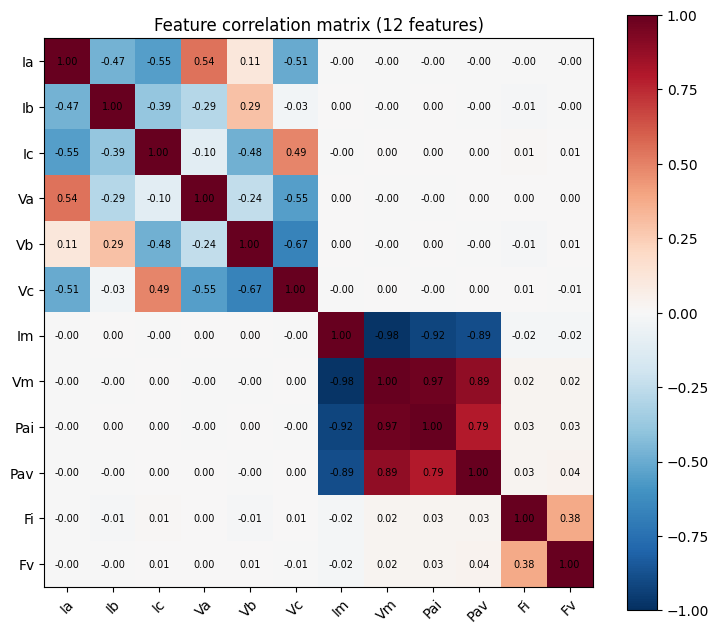


The cluster the paper drops:
  Im-Vm: -0.98
  Vm-Pai: +0.97
  Im-Pai: -0.92
  Im-Pav: -0.89
  Vm-Pav: +0.89
  Pai-Pav: +0.79
Phase quantities vs that cluster: |r| < 0.02  ->  two independent information layers.


In [3]:
ALL12 = ['Ia','Ib','Ic','Va','Vb','Vc','Im','Vm','Pai','Pav','Fi','Fv']
corr = df[ALL12].corr()
print(corr.round(2).to_string())

plt.figure(figsize=(7.5,6.5))
plt.imshow(corr, cmap='RdBu_r', vmin=-1, vmax=1)
plt.xticks(range(12), ALL12, rotation=45)
plt.yticks(range(12), ALL12)
for i in range(12):
    for j in range(12):
        plt.text(j, i, f'{corr.iloc[i,j]:.2f}', ha='center', va='center', fontsize=7)
plt.colorbar()
plt.title('Feature correlation matrix (12 features)')
plt.tight_layout()
plt.show()

print('\nThe cluster the paper drops:')
for a,b in [('Im','Vm'),('Vm','Pai'),('Im','Pai'),('Im','Pav'),('Vm','Pav'),('Pai','Pav')]:
    print(f'  {a}-{b}: {corr.loc[a,b]:+.2f}')
print('Phase quantities vs that cluster: |r| < 0.02  ->  two independent information layers.')

### Cell 4 — Feature set, labels, split, scaling, PCA

In [4]:
FEATS = ['Ia','Ib','Ic','Va','Vb','Vc','Fi','Fv','Pai']
le = LabelEncoder()
X = df[FEATS]
y = le.fit_transform(df['fault_types'])
CLASSES = list(le.classes_)
print('classes:', CLASSES)

Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.2, random_state=RS, stratify=y)

sc  = StandardScaler().fit(Xtr)
pca = PCA(n_components=9).fit(sc.transform(Xtr))
Xtr_p, Xte_p = pca.transform(sc.transform(Xtr)), pca.transform(sc.transform(Xte))
Xr_tr, Xr_te = Xtr.values, Xte.values

print('train', Xtr_p.shape, ' test', Xte_p.shape)
print('explained variance (cumulative):', np.round(np.cumsum(pca.explained_variance_ratio_),4))

classes: ['LG', 'LL', 'LLG', 'LLL', 'LLLG', 'NF']
train (107215, 9)  test (26804, 9)
explained variance (cumulative): [0.2881 0.4987 0.6517 0.7623 0.8472 0.9256 0.9952 0.9995 1.    ]


## Part B — Reproduction
### Cell 5 — The paper's three strong models and the soft-voting ensemble

In [5]:
def report(name, pred, note=''):
    print(f'{name:22} acc {accuracy_score(yte,pred)*100:6.2f}'
          f'  prec {precision_score(yte,pred,average="weighted")*100:6.2f}'
          f'  rec {recall_score(yte,pred,average="weighted")*100:6.2f}'
          f'  f1 {f1_score(yte,pred,average="weighted")*100:6.2f}  {note}')

dt  = DecisionTreeClassifier(random_state=RS).fit(Xtr_p, ytr)
rf  = RandomForestClassifier(random_state=RS, n_jobs=-1).fit(Xtr_p, ytr)
knn = KNeighborsClassifier().fit(Xtr_p, ytr)
em  = VotingClassifier([('dt', DecisionTreeClassifier(random_state=RS)),
                        ('rf', RandomForestClassifier(random_state=RS, n_jobs=-1)),
                        ('knn', KNeighborsClassifier())], voting='soft').fit(Xtr_p, ytr)

for n, m in [('Decision Tree',dt), ('Random Forest',rf),
             ('K-Nearest Neighbour',knn), ('Ensemble (soft vote)',em)]:
    report(n, m.predict(Xte_p))
print('\nNote: RF alone matches or beats the ensemble, so the ensemble is not strictly best.')

Decision Tree          acc  99.89  prec  99.89  rec  99.89  f1  99.89  
Random Forest          acc  99.96  prec  99.96  rec  99.96  f1  99.96  


K-Nearest Neighbour    acc  99.82  prec  99.82  rec  99.82  f1  99.82  


Ensemble (soft vote)   acc  99.94  prec  99.94  rec  99.94  f1  99.94  

Note: RF alone matches or beats the ensemble, so the ensemble is not strictly best.


### Cell 6 — The four models the paper reports as weak

`SVC` and `GB` are subsampled for tractability (SVC is ~O(n^2)); the test set is always full.

In [6]:
sub = np.random.RandomState(0).choice(len(Xtr_p), 12000, replace=False)

gb  = GradientBoostingClassifier(random_state=RS).fit(Xtr_p[sub], ytr[sub])
mlp = MLPClassifier(random_state=RS, max_iter=300).fit(Xtr_p, ytr)
gnb = GaussianNB().fit(Xtr_p, ytr)
svc = SVC(random_state=RS).fit(Xtr_p[sub], ytr[sub])
lsv = LinearSVC(random_state=RS, max_iter=5000).fit(Xtr_p[sub], ytr[sub])

PAPER = {'GB':97.88, 'MLP':95.64, 'GNB':95.21, 'SVC-OvO':92.19, 'SVC-OvR':86.83}
scaled = {}
for n, m in [('GB',gb), ('MLP',mlp), ('GNB',gnb), ('SVC-OvO',svc), ('SVC-OvR',lsv)]:
    scaled[n] = accuracy_score(yte, m.predict(Xte_p))*100
    print(f'{n:9} ours {scaled[n]:6.2f}   paper {PAPER[n]:6.2f}   gap {scaled[n]-PAPER[n]:+6.2f}')
print('\nGaps of 2-7 points cannot come from a random seed or a library version.')

GB        ours  99.59   paper  97.88   gap  +1.71
MLP       ours  99.99   paper  95.64   gap  +4.35
GNB       ours  99.39   paper  95.21   gap  +4.18


SVC-OvO   ours  99.53   paper  92.19   gap  +7.34
SVC-OvR   ours  84.05   paper  86.83   gap  -2.78

Gaps of 2-7 points cannot come from a random seed or a library version.


### Cell 7 — Audit I/II: is the gap caused by preprocessing?

Hypothesis: in the base paper the strong models received scaled + PCA features while the
weak ones received raw features. We test it by re-running the same estimators on raw data.

In [7]:
def raw_acc(model, subsample=None):
    A, b = (Xr_tr[sub], ytr[sub]) if subsample else (Xr_tr, ytr)
    model.fit(A, b)
    return accuracy_score(yte, model.predict(Xr_te))*100

rawres = {
 'GB'     : raw_acc(GradientBoostingClassifier(random_state=RS), True),
 'MLP'    : raw_acc(MLPClassifier(random_state=RS, max_iter=300)),
 'GNB'    : raw_acc(GaussianNB()),
 'SVC-OvO': raw_acc(SVC(random_state=RS), True),
 'SVC-OvR': raw_acc(LinearSVC(random_state=RS, max_iter=5000), True),
}
print(f"{'Model':9}{'Paper':>8}{'Scaled':>9}{'Raw':>9}{'|d|scaled':>11}{'|d|raw':>9}   Closer")
for n in PAPER:
    ds, dr = abs(scaled[n]-PAPER[n]), abs(rawres[n]-PAPER[n])
    print(f'{n:9}{PAPER[n]:8.2f}{scaled[n]:9.2f}{rawres[n]:9.2f}{ds:11.2f}{dr:9.2f}   '
          f'{"raw" if dr < ds else "scaled"}')
print('\nPreprocessing sensitivity (scaled minus raw):')
for n in PAPER:
    print(f'  {n:9}{scaled[n]-rawres[n]:+7.2f}')

print(f'''
Reading:
 * SVC-OvO is the clearest preprocessing artefact: {scaled["SVC-OvO"]:.1f} scaled vs {rawres["SVC-OvO"]:.1f} raw.
   Removing standardisation costs it {scaled["SVC-OvO"]-rawres["SVC-OvO"]:.1f} points and moves it toward the
   published figure of {PAPER["SVC-OvO"]:.1f}.
 * SVC-OvR sits near the published {PAPER["SVC-OvR"]:.1f} in BOTH columns, so its weakness is the linear
   kernel, not the preprocessing. Preprocessing is not the whole story.
 * MLP and GNB exceed the published figures in both columns. We report this rather than
   explain it away; MLP on raw data is also unstable across runs despite a fixed seed.
 * The defensible claim is therefore about sensitivity, not exact reproduction: a difference
   in preprocessing moves a single estimator by more than the reported spread between
   estimators, so that spread cannot be read as a difference in model capability.''')

Model       Paper   Scaled      Raw  |d|scaled   |d|raw   Closer
GB          97.88    99.59    99.75       1.71     1.87   scaled
MLP         95.64    99.99    89.49       4.35     6.15   scaled
GNB         95.21    99.39    99.72       4.18     4.51   scaled
SVC-OvO     92.19    99.53    87.77       7.34     4.42   raw
SVC-OvR     86.83    84.05    84.01       2.78     2.82   scaled

Preprocessing sensitivity (scaled minus raw):
  GB         -0.16
  MLP       +10.49
  GNB        -0.33
  SVC-OvO   +11.76
  SVC-OvR    +0.05

Reading:
 * SVC-OvO is the clearest preprocessing artefact: 99.5 scaled vs 87.8 raw.
   Removing standardisation costs it 11.8 points and moves it toward the
   published figure of 92.2.
 * SVC-OvR sits near the published 86.8 in BOTH columns, so its weakness is the linear
   kernel, not the preprocessing. Preprocessing is not the whole story.
 * MLP and GNB exceed the published figures in both columns. We report this rather than
   explain it away; MLP on raw data 

### Cell 8 — Cross-validation (overfitting check)

In [8]:
for n, m in [('DT ', DecisionTreeClassifier(random_state=RS)),
             ('RF ', RandomForestClassifier(random_state=RS, n_jobs=-1)),
             ('KNN', KNeighborsClassifier())]:
    s = cross_val_score(m, Xtr_p, ytr, cv=5, n_jobs=-1)
    print(f'{n} 5-fold CV {s.mean()*100:6.2f}  (+/- {s.std()*100:.2f})')
print('\nCV matches the held-out test accuracy -> no evidence of overfitting.')

DT  5-fold CV  99.89  (+/- 0.03)


RF  5-fold CV  99.97  (+/- 0.02)


KNN 5-fold CV  99.82  (+/- 0.03)

CV matches the held-out test accuracy -> no evidence of overfitting.


### Cell 9 — Confusion matrices

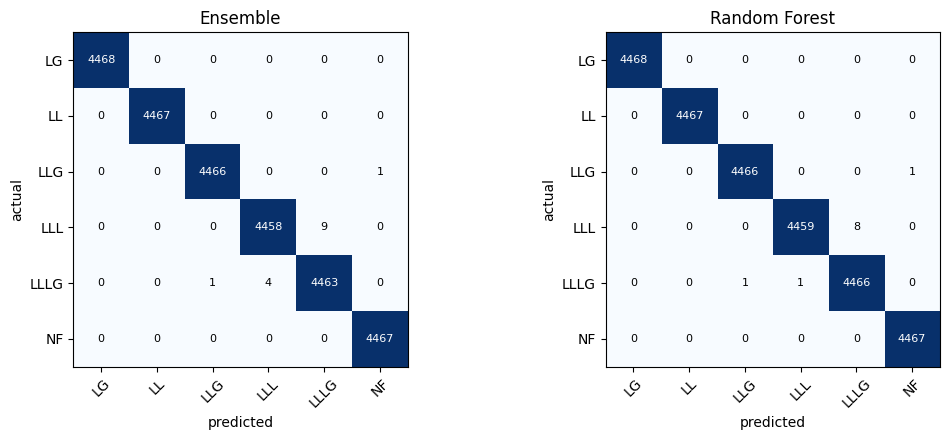

              precision    recall  f1-score   support

          LG     1.0000    1.0000    1.0000      4468
          LL     1.0000    1.0000    1.0000      4467
         LLG     0.9998    0.9998    0.9998      4467
         LLL     0.9998    0.9982    0.9990      4467
        LLLG     0.9982    0.9996    0.9989      4468
          NF     0.9998    1.0000    0.9999      4467

    accuracy                         0.9996     26804
   macro avg     0.9996    0.9996    0.9996     26804
weighted avg     0.9996    0.9996    0.9996     26804



In [9]:
def cm_plot(model, title, ax):
    cm = confusion_matrix(yte, model.predict(Xte_p))
    ax.imshow(cm, cmap='Blues')
    for i in range(len(CLASSES)):
        for j in range(len(CLASSES)):
            ax.text(j, i, cm[i,j], ha='center', va='center', fontsize=8,
                    color='white' if cm[i,j] > cm.max()/2 else 'black')
    ax.set_xticks(range(len(CLASSES)))
    ax.set_xticklabels(CLASSES, rotation=45)
    ax.set_yticks(range(len(CLASSES)))
    ax.set_yticklabels(CLASSES)
    ax.set_xlabel('predicted')
    ax.set_ylabel('actual')
    ax.set_title(title)

fig, axes = plt.subplots(1, 2, figsize=(11,4.5))
cm_plot(em, 'Ensemble', axes[0])
cm_plot(rf, 'Random Forest', axes[1])
plt.tight_layout()
plt.show()
print(classification_report(yte, rf.predict(Xte_p), target_names=CLASSES, digits=4))

### Cell 10 — ROC curves (one-vs-rest)

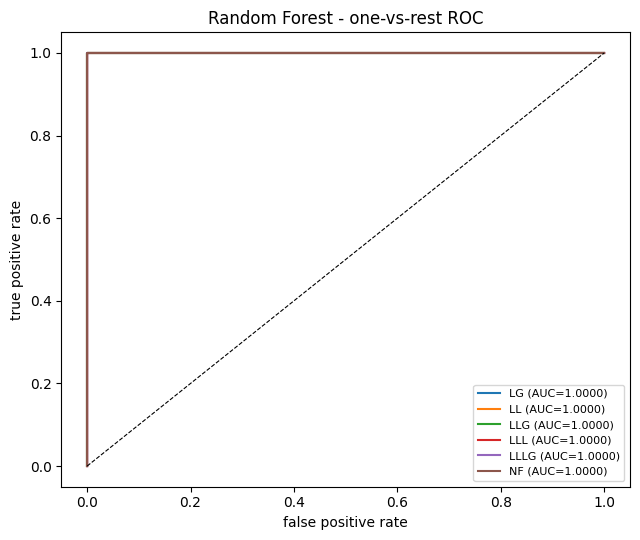

In [10]:
Yb = label_binarize(yte, classes=range(len(CLASSES)))
proba = rf.predict_proba(Xte_p)
plt.figure(figsize=(6.5,5.5))
for i, c in enumerate(CLASSES):
    fpr, tpr, _ = roc_curve(Yb[:,i], proba[:,i])
    plt.plot(fpr, tpr, label=f'{c} (AUC={auc(fpr,tpr):.4f})')
plt.plot([0,1],[0,1],'k--', lw=.8)
plt.xlabel('false positive rate')
plt.ylabel('true positive rate')
plt.title('Random Forest - one-vs-rest ROC')
plt.legend(fontsize=8)
plt.tight_layout()
plt.show()

### Cell 11 — SHAP

Trained on **raw** features, not PCA components, so that the attributions map onto named
PMU quantities rather than anonymous principal components.

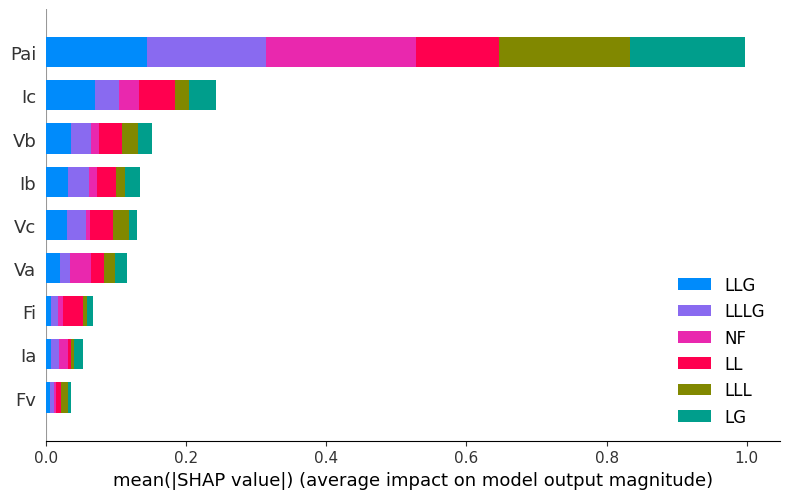

If one feature dominates, the model is matching a band, not learning fault physics.


In [11]:
try:
    import shap
except ImportError:
    !pip install shap -q
    import shap

rf_raw = RandomForestClassifier(random_state=RS, n_jobs=-1).fit(Xtr, ytr)
sample = Xte.sample(300, random_state=0)
sv = shap.TreeExplainer(rf_raw).shap_values(sample)
shap.summary_plot(sv, sample, plot_type='bar', class_names=CLASSES, show=True)
print('If one feature dominates, the model is matching a band, not learning fault physics.')

### Cell 12 — Reproduction versus reported values

In [12]:
paper_head = {'DT':99.87, 'RF':99.86, 'KNN':99.78, 'EM':99.92}
ours = {'DT': accuracy_score(yte, dt.predict(Xte_p))*100,
        'RF': accuracy_score(yte, rf.predict(Xte_p))*100,
        'KNN':accuracy_score(yte, knn.predict(Xte_p))*100,
        'EM': accuracy_score(yte, em.predict(Xte_p))*100}
print(f"{'Model':6}{'Ours':>9}{'Paper':>9}{'Diff':>9}")
for k in paper_head:
    print(f'{k:6}{ours[k]:9.2f}{paper_head[k]:9.2f}{ours[k]-paper_head[k]:+9.2f}')

Model      Ours    Paper     Diff
DT        99.89    99.87    +0.02
RF        99.96    99.86    +0.10
KNN       99.82    99.78    +0.04
EM        99.94    99.92    +0.02


## Part C — Audit
### Cell 13 — Temporal evaluation: what the headline accuracy hides

Random splitting places adjacent, nearly identical samples in both train and test. Here we
split along the timeline instead.

In [13]:
def split_by_time(d, frac, test_first):
    tri, tei = [], []
    for _, g in d.groupby('fault_types'):
        g = g.sort_values('time_stamp')
        cut = max(1, int(len(g)*frac))
        if test_first:
            tei += list(g.index[:cut])
            tri += list(g.index[cut:])
        else:
            tri += list(g.index[:cut])
            tei += list(g.index[cut:])
    return d.loc[tri], d.loc[tei]

d = df.copy()
d['y'] = y
def rf_acc(tr, te):
    m = RandomForestClassifier(random_state=RS, n_jobs=-1).fit(tr[FEATS], tr['y'])
    return round(accuracy_score(te['y'], m.predict(te[FEATS]))*100, 2), m

a, m0 = rf_acc(*[d.loc[i] for i in
                 train_test_split(d.index, test_size=.2, random_state=RS, stratify=d['y'])])
print(f'random split (paper protocol)      {a}')

te_r = d.loc[train_test_split(d.index, test_size=.2, random_state=RS, stratify=d['y'])[1]].copy()
te_r['pred'] = m0.predict(te_r[FEATS])
te_r['decile'] = te_r.groupby('fault_types')['time_stamp'].rank(pct=True).mul(10).astype(int).clip(0,9)
wrong = te_r[te_r.pred != te_r.y]
print(f'  errors {len(wrong)} of {len(te_r)}  ->  by decile {wrong.groupby("decile").size().to_dict()}')

print(f'temporal hold-out (test = last 20%) {rf_acc(*split_by_time(d, .8, False))[0]}')
print(f'out-of-regime     (test = first 20%){rf_acc(*split_by_time(d, .2, True))[0]}')
print(f'early window      (test = first 1%) {rf_acc(*split_by_time(d, .01, True))[0]}')

tr_i, te_i = train_test_split(d.index, test_size=.2, random_state=RS, stratify=d['y'])
for f in ['Pai','Va','Ia']:
    m = DecisionTreeClassifier(max_depth=4, random_state=RS).fit(d.loc[tr_i,[f]], d.loc[tr_i,'y'])
    print(f'single feature {f:4} depth-4 tree  {accuracy_score(d.loc[te_i,"y"], m.predict(d.loc[te_i,[f]]))*100:6.2f}')

random split (paper protocol)      100.0
  errors 1 of 26804  ->  by decile {0: 1}


temporal hold-out (test = last 20%) 100.0


out-of-regime     (test = first 20%)85.77


early window      (test = first 1%) 76.98
single feature Pai  depth-4 tree   99.54
single feature Va   depth-4 tree   45.34


single feature Ia   depth-4 tree   42.48


### Cell 14 — Why we do not apply IQR outlier removal

The paper reports IQR filtering. On fault data the outliers *are* the faults, so we test
both variants before deciding.

In [14]:
def iqr_filter(d0, k=1.5, per_class=False):
    def mask(b):
        m = pd.Series(True, index=b.index)
        for c in FEATS:
            q1, q3 = b[c].quantile([.25,.75])
            m &= b[c].between(q1-k*(q3-q1), q3+k*(q3-q1))
        return m
    if per_class:
        keep = pd.concat([mask(g) for _, g in d0.groupby('fault_types')])
        return d0[keep.reindex(d0.index)]
    return d0[mask(d0)]

def quick(d0, tag):
    counts = d0['fault_types'].value_counts()
    if counts.min() < 2 or len(counts) < len(CLASSES):
        lost = [c for c in CLASSES if counts.get(c, 0) < 2]
        print(f'{tag:24} rows {len(d0):>7}  not evaluable - '
              f'classes {lost} reduced below two samples')
        return
    Xa, ya = d0[FEATS], d0['y']
    A, B, ta, tb = train_test_split(Xa, ya, test_size=.2, random_state=RS, stratify=ya)
    s = StandardScaler().fit(A)
    p = PCA(n_components=9).fit(s.transform(A))
    A2, B2 = p.transform(s.transform(A)), p.transform(s.transform(B))
    out = {n: round(accuracy_score(tb, m.fit(A2, ta).predict(B2))*100, 2)
           for n, m in [('DT',DecisionTreeClassifier(random_state=RS)),
                        ('RF',RandomForestClassifier(random_state=RS,n_jobs=-1)),
                        ('KNN',KNeighborsClassifier())]}
    print(f'{tag:24} rows {len(d0):>7}  {out}')

quick(d, 'no IQR (our choice)')
g_ = iqr_filter(d)
print('  global   survivors:', g_.fault_types.value_counts().to_dict())
quick(g_, 'global IQR k=1.5')
p_ = iqr_filter(d, per_class=True)
print('  per-class survivors:', p_.fault_types.value_counts().to_dict())
quick(p_, 'per-class IQR k=1.5')
print('''
Global IQR deletes most of LL and LLL because the most severe faults are the statistical
outliers. Per-class IQR keeps the balance but removes the transient samples and pushes every
model to 100%. Either way outlier removal makes the benchmark easier, so we keep raw data.''')

no IQR (our choice)      rows  134019  {'DT': 99.89, 'RF': 99.96, 'KNN': 99.82}
  global   survivors: {'LG': 20722, 'LLG': 20255, 'LLLG': 16691, 'NF': 15957, 'LLL': 1815, 'LL': 1415}


global IQR k=1.5         rows   76855  {'DT': 99.91, 'RF': 99.97, 'KNN': 99.86}
  per-class survivors: {'LLL': 20632, 'LG': 20543, 'LLLG': 20156, 'LLG': 18680, 'LL': 17487, 'NF': 17172}


per-class IQR k=1.5      rows  114670  {'DT': 100.0, 'RF': 100.0, 'KNN': 100.0}

Global IQR deletes most of LL and LLL because the most severe faults are the statistical
outliers. Per-class IQR keeps the balance but removes the transient samples and pushes every
model to 100%. Either way outlier removal makes the benchmark easier, so we keep raw data.


## Part D — Extension
### Cell 15 — Perturbation suite: noise, packet loss and false data injection

Three ways a real PMU stream degrades, applied to the *test* set only (the model is trained
on clean data, as it would be in deployment).

In [15]:
def awgn(Z, snr_db, rng):
    p = np.mean(Z**2, axis=0)
    return Z + rng.normal(0, np.sqrt(p/(10**(snr_db/10))), Z.shape)

def packet_loss(Z, frac, rng):
    Z = Z.copy()
    n, k = Z.shape
    miss = rng.random((n, k)) < frac
    for j in range(k):
        idx = np.where(miss[:, j])[0]
        for i in idx:
            Z[i, j] = Z[i-1, j] if i > 0 else Z[i, j]
    return Z

def fdi(Z, frac, scale, rng, col=None):
    Z = Z.copy()
    n, k = Z.shape
    rows = rng.choice(n, int(frac*n), replace=False)
    cols = rng.integers(0, k, len(rows)) if col is None else np.full(len(rows), col)
    Z[rows, cols] *= scale
    return Z

base = RandomForestClassifier(random_state=RS, n_jobs=-1).fit(Xtr, ytr)
rng = np.random.default_rng(0)
clean = accuracy_score(yte, base.predict(Xr_te))*100
print(f'clean                        {clean:6.2f}\n')

print('additive white Gaussian noise')
for snr in [40, 30, 20, 10]:
    print(f'  SNR {snr:3d} dB               {accuracy_score(yte, base.predict(awgn(Xr_te, snr, rng)))*100:6.2f}')
print('\npacket loss (hold last value)')
for fr in [.05, .10, .15, .25]:
    print(f'  {fr*100:4.0f}% samples lost       {accuracy_score(yte, base.predict(packet_loss(Xr_te, fr, rng)))*100:6.2f}')
print('\nfalse data injection - random channel')
for fr, sc_ in [(.05,1.2), (.10,2.0)]:
    print(f'  {fr*100:4.0f}% rows, x{sc_}          {accuracy_score(yte, base.predict(fdi(Xr_te, fr, sc_, rng)))*100:6.2f}')

dom = int(np.argmax(base.feature_importances_))
print(f'\nfalse data injection - targeted at the dominant channel ({FEATS[dom]})')
for fr, sc_ in [(.05,1.2), (.10,1.2), (.10,2.0), (.25,2.0)]:
    print(f'  {fr*100:4.0f}% rows, x{sc_}          '
          f'{accuracy_score(yte, base.predict(fdi(Xr_te, fr, sc_, rng, col=dom)))*100:6.2f}')
print('''
A random-channel spoof barely moves the accuracy, because the model leans on very few
features. Targeting that dominant channel is the attack that matters - and it is exactly the
attack a saturated, single-feature-separable benchmark is most exposed to.''')

clean                        100.00

additive white Gaussian noise
  SNR  40 dB                99.18
  SNR  30 dB                97.23
  SNR  20 dB                89.29


  SNR  10 dB                63.11

packet loss (hold last value)
     5% samples lost        96.43
    10% samples lost        93.00
    15% samples lost        89.32


    25% samples lost        80.82

false data injection - random channel
     5% rows, x1.2           99.94
    10% rows, x2.0           99.72

false data injection - targeted at the dominant channel (Pai)
     5% rows, x1.2           99.71


    10% rows, x1.2           99.40
    10% rows, x2.0           97.30
    25% rows, x2.0           93.36

A random-channel spoof barely moves the accuracy, because the model leans on very few
features. Targeting that dominant channel is the attack that matters - and it is exactly the
attack a saturated, single-feature-separable benchmark is most exposed to.


### Cell 16 — A parametric fault-waveform generator

The base dataset holds one operating point per class, which is why it saturates. Here we
build a replacement from symmetrical-component theory, sweeping five parameters:
fault location, fault resistance, inception angle, source strength and loading.

No Simulink required — the sequence-network equations are closed form.

In [16]:
import numpy as np
A_OP  = np.exp(2j*np.pi/3)
A_MAT = np.array([[1,1,1],[1,A_OP**2,A_OP],[1,A_OP,A_OP**2]])
F0, FS = 50.0, 3200.0
W0 = 2*np.pi*F0
N_CYC = int(FS/F0)

def seq_currents(kind, Z1, Z2, Z0, E, Rf):
    if kind == 'NF':
        return 0j, 0j, 0j
    if kind in ('LLL','LLLG'):
        return 0j, E/(Z1+Rf), 0j
    if kind == 'LG':
        I = E/(Z1+Z2+Z0+3*Rf)
        return I, I, I
    if kind == 'LL':
        I = E/(Z1+Z2+2*Rf)
        return 0j, I, -I
    if kind == 'LLG':
        Zp = (Z2*(Z0+3*Rf))/(Z2+Z0+3*Rf)
        I1 = E/(Z1+Rf+Zp)
        return (-I1*Z2/(Z2+Z0+3*Rf), I1, -I1*(Z0+3*Rf)/(Z2+Z0+3*Rf))
    raise ValueError(kind)

def run_case(kind, m=.5, Rf=.5, theta0=0., scr=10., load=1.,
             Vll=132., dur=.25, t_fault=.06):
    Vph   = Vll*1e3/np.sqrt(3)
    Zbase = (Vll*1e3)**2/100e6
    ZL1   = (0.03+0.30j)*Zbase
    ZL0   = 3.0*ZL1.real + 2.7j*ZL1.imag
    Zs1, Zs0 = ZL1/scr, 1.2*ZL1/scr
    Zload = Vph/(load*Vph/abs(ZL1)*0.6 + 1e-9)

    Zsrc1, Zsrc0 = Zs1 + m*ZL1, Zs0 + m*ZL0
    Zrem1, Zrem0 = (1-m)*ZL1 + Zload, (1-m)*ZL0 + Zload
    par = lambda a, b: a*b/(a+b)
    Z1th = Z2th = par(Zsrc1, Zrem1)
    Z0th = par(Zsrc0, Zrem0)
    div1, div0 = Zrem1/(Zsrc1+Zrem1), Zrem0/(Zsrc0+Zrem0)

    Iload   = Vph/(Zs1+ZL1+Zload)*load
    Iph_pre = Iload*np.array([1, A_OP**2, A_OP])
    Vph_pre = Vph *np.array([1, A_OP**2, A_OP])
    Vf0 = Vph*Zrem1/(Zsrc1+Zrem1)

    dI0, dI1, dI2 = seq_currents(kind, Z1th, Z2th, Z0th, Vf0, Rf)
    Iph_f = A_MAT @ np.array([dI0*div0, dI1*div1, dI2*div1]) + Iph_pre
    Vph_f = Vph_pre - (A_MAT @ np.array([dI0*div0*Zs0, dI1*div1*Zs1, dI2*div1*Zs1]))
    if kind == 'NF':
        Iph_f, Vph_f = Iph_pre, Vph_pre

    n = int(dur*FS)
    t = np.arange(n)/FS
    Rs_, Ls_ = Zsrc1.real, Zsrc1.imag/W0
    Rr_, Lr_ = Zrem1.real, Zrem1.imag/W0
    _r = np.roots([Ls_*Lr_,
                   Rs_*Lr_ + Rr_*Ls_ + Rf*(Ls_+Lr_),
                   Rs_*Rr_ + Rf*(Rs_+Rr_)])
    _r = _r.real[_r.real < 0]
    tau = float(-1.0/np.max(_r)) if _r.size else Ls_/max(Rs_, 1e-6)
    on = t >= t_fault
    I = np.zeros((n,3))
    V = np.zeros((n,3))
    for k in range(3):
        pi_ = np.sqrt(2)*abs(Iph_pre[k])*np.cos(W0*t+theta0+np.angle(Iph_pre[k]))
        fi_ = np.sqrt(2)*abs(Iph_f[k])  *np.cos(W0*t+theta0+np.angle(Iph_f[k]))
        dc0 = (pi_[on][0]-fi_[on][0]) if on.any() else 0.
        dc  = np.zeros(n)
        dc[on] = dc0*np.exp(-(t[on]-t_fault)/max(tau,1e-4))
        I[:,k] = np.where(on, fi_+dc, pi_)
        pv = np.sqrt(2)*abs(Vph_pre[k])*np.cos(W0*t+theta0+np.angle(Vph_pre[k]))
        fv = np.sqrt(2)*abs(Vph_f[k])  *np.cos(W0*t+theta0+np.angle(Vph_f[k]))
        V[:,k] = np.where(on, fv, pv)
    return dict(t=t, I=I, V=V, Iph=Iph_f, Vph=Vph_f, t_fault=t_fault,
                Z1f=Zsrc1, Z1th=Z1th, E=Vph, Vf0=Vf0, tau=tau)

def fault_component(kind, m=.5, Rf=.5, scr=10., load=1., Vll=132.):
    Vph = Vll*1e3/np.sqrt(3)
    Zb = (Vll*1e3)**2/100e6
    ZL1 = (0.03+0.30j)*Zb
    ZL0 = 3.0*ZL1.real + 2.7j*ZL1.imag
    Zs1, Zs0 = ZL1/scr, 1.2*ZL1/scr
    Zload = Vph/(load*Vph/abs(ZL1)*0.6 + 1e-9)
    Zsrc1, Zsrc0 = Zs1 + m*ZL1, Zs0 + m*ZL0
    Zrem1, Zrem0 = (1-m)*ZL1 + Zload, (1-m)*ZL0 + Zload
    par = lambda a, b: a*b/(a+b)
    Z1th = Z2th = par(Zsrc1, Zrem1)
    Z0th = par(Zsrc0, Zrem0)
    Vf0 = Vph*Zrem1/(Zsrc1+Zrem1)
    I0, I1, I2 = seq_currents(kind, Z1th, Z2th, Z0th, Vf0, Rf)
    return np.abs(A_MAT @ np.array([I0, I1, I2]))

r = run_case('LLL', m=1e-6, Rf=0., scr=1e6, load=1e-6)
assert abs(abs(r['Iph'][0]) - abs(r['E']/r['Z1th'])) < 1e-3*abs(r['E']/r['Z1th'])
print('validation 1  bolted 3-phase at the terminals = E/Z1        OK')

i3 = fault_component('LLL', m=.5, Rf=0.)[0]
i1 = fault_component('LG',  m=.5, Rf=0.)[0]
assert i1 < i3
print(f'validation 2  SLG {i1:.0f} A  <  three-phase {i3:.0f} A               OK')

rf = [fault_component('LG', Rf=x)[0] for x in [0, 1, 5, 10, 20, 50]]
assert all(np.diff(rf) < 0)
print('validation 3  Rf sweep :', [f'{v:.0f}' for v in rf], 'A   monotone')

ms = [fault_component('LG', m=x)[0] for x in [.05, .25, .5, .75, .95]]
assert all(np.diff(ms) < 0)
print('validation 4  m  sweep :', [f'{v:.0f}' for v in ms], 'A   monotone')

assert np.allclose(fault_component('LLL', Rf=1.), fault_component('LLLG', Rf=1.))
print('validation 5  LLL == LLLG                                    OK')

_tau = [run_case('LG', m=.5, Rf=x)['tau']*1e3 for x in [0, 1, 5, 20, 50]]
assert all(np.diff(_tau) < 0)
print('validation 6  dc time constant vs Rf:',
      [f'{v:.1f}' for v in _tau], 'ms   monotone')

print('\nSection IV-D numbers (fault current at the fault point):')
print(f'  SLG {i1:.0f} A vs three-phase {i3:.0f} A at m=0.5')
print(f'  Rf: {rf[0]:.0f} A at 0 ohm -> {rf[-1]:.0f} A at 50 ohm')
print(f'  m : {ms[0]:.0f} A at m=0.05 -> {ms[-1]:.0f} A at m=0.95')

print('\nTerminal currents at Bus A, reference point (compare with Simulink):')
for k in ['NF','LG','LL','LLG','LLL','LLLG']:
    v = np.abs(run_case(k, m=.5, Rf=1., scr=10., load=1.)['Iph'])
    print(f'  {k:5} |Ia|={v[0]:8.1f}  |Ib|={v[1]:8.1f}  |Ic|={v[2]:8.1f} A')

validation 1  bolted 3-phase at the terminals = E/Z1        OK
validation 2  SLG 1868 A  <  three-phase 2418 A               OK
validation 3  Rf sweep : ['1868', '1847', '1756', '1636', '1403', '916'] A   monotone
validation 4  m  sweep : ['7849', '3079', '1858', '1391', '1173'] A   monotone
validation 5  LLL == LLLG                                    OK
validation 6  dc time constant vs Rf: ['31.8', '24.2', '12.7', '5.3', '3.2'] ms   monotone

Section IV-D numbers (fault current at the fault point):
  SLG 1868 A vs three-phase 2418 A at m=0.5
  Rf: 1868 A at 0 ohm -> 916 A at 50 ohm
  m : 7849 A at m=0.05 -> 1173 A at m=0.95

Terminal currents at Bus A, reference point (compare with Simulink):
  NF    |Ia|=   695.4  |Ib|=   695.4  |Ic|=   695.4 A
  LG    |Ia|=  1856.8  |Ib|=   651.3  |Ic|=   819.5 A
  LL    |Ia|=   695.4  |Ib|=  2366.1  |Ic|=  1829.7 A
  LLG   |Ia|=   760.2  |Ib|=  2368.5  |Ic|=  2065.1 A
  LLL   |Ia|=  2408.9  |Ib|=  2408.9  |Ic|=  2408.9 A
  LLLG  |Ia|=  2408.9  |Ib

### Cell 17 — Build the parametric dataset

A one-cycle sliding DFT reproduces the PMU phasor outputs (`Im`, `Vm`, `Pai`, `Pav`, `Fi`, `Fv`)
so the schema matches the base dataset exactly. **Runtime ~10-20 min.** Lower
`N_PER_CLASS` if you are short of time.

In [17]:
def pmu_stream(x, fs=FS, f0=F0):
    n = len(x)
    N = int(fs/f0)
    k = np.exp(-2j*np.pi*np.arange(N)/N)
    mag = np.full(n, np.nan)
    ang = np.full(n, np.nan)
    ph = np.zeros(n, complex)
    for i in range(N-1, n):
        Xk = (2/N)*np.dot(x[i-N+1:i+1], k)
        ph[i] = Xk
        mag[i] = abs(Xk)/np.sqrt(2)
        ang[i] = np.angle(Xk, deg=True)
    dfreq = np.gradient(np.unwrap(np.angle(ph)))*fs/(2*np.pi)
    return mag, ang, f0 + np.nan_to_num(dfreq)

def make_run(kind, **kw):
    r = run_case(kind, **kw)
    o = {'time_stamp': r['t']}
    for j, p in enumerate('abc'):
        o['I'+p] = r['I'][:,j]
        o['V'+p] = r['V'][:,j]
    mi, ai, fi = pmu_stream(r['I'][:,0])
    mv, av, fv = pmu_stream(r['V'][:,0])
    o.update(Im=mi, Pai=ai, Fi=fi, Vm=mv, Pav=av, Fv=fv)
    out = pd.DataFrame(o)
    out['fault_types'] = kind
    out['t_fault'] = r['t_fault']
    return out.iloc[N_CYC-1:].reset_index(drop=True)

N_PER_CLASS = 50
rng = np.random.default_rng(0)
runs = []
for kind in CLASSES:
    for _ in range(N_PER_CLASS):
        runs.append(make_run(kind,
            m=rng.uniform(.05,.95),
            Rf=float(rng.choice([0,1,5,10,25,50], p=[.2,.2,.2,.15,.15,.1])),
            theta0=rng.uniform(0, 2*np.pi),
            scr=rng.uniform(3,25),
            load=rng.uniform(.3,1.2)))
gen = pd.concat(runs, ignore_index=True)
gen['y'] = le.transform(gen['fault_types'])
print(gen.shape, gen.fault_types.value_counts().to_dict())
gen.to_csv('parametric_pmu_faults.csv', index=False)
print('saved -> parametric_pmu_faults.csv')

(221100, 16) {'LG': 36850, 'LL': 36850, 'LLG': 36850, 'LLL': 36850, 'LLLG': 36850, 'NF': 36850}


saved -> parametric_pmu_faults.csv


### Cell 18 — Saturation diagnostic on both datasets

Three cheap checks any fault benchmark should pass. If a single feature or a depth-4 tree
lands within a point of the proposed model, the benchmark cannot discriminate methods.

In [18]:
def diagnostics(d0, tag, feats=FEATS):
    post = d0[d0.time_stamp >= d0.t_fault] if 't_fault' in d0 else d0
    A, B, ta, tb = train_test_split(post[feats], post['y'], test_size=.2,
                                    random_state=RS, stratify=post['y'])
    full = accuracy_score(tb, RandomForestClassifier(random_state=RS, n_jobs=-1)
                          .fit(A, ta).predict(B))*100
    d4   = accuracy_score(tb, DecisionTreeClassifier(max_depth=4, random_state=RS)
                          .fit(A, ta).predict(B))*100
    best_f, best_a = None, -1
    for f in feats:
        a = accuracy_score(tb, DecisionTreeClassifier(max_depth=4, random_state=RS)
                           .fit(A[[f]], ta).predict(B[[f]]))*100
        if a > best_a:
            best_f, best_a = f, a
    print(f'{tag:26} RF {full:6.2f} | depth-4 tree {d4:6.2f} | best single feature '
          f'{best_f} {best_a:6.2f}  -> {"SATURATED" if best_a > full-1 else "discriminative"}')

diagnostics(d,   'base dataset (Dryad)')
diagnostics(gen, 'parametric dataset (ours)')

base dataset (Dryad)       RF 100.00 | depth-4 tree  99.54 | best single feature Pai  99.54  -> SATURATED


parametric dataset (ours)  RF  98.84 | depth-4 tree  50.59 | best single feature Ic  33.11  -> discriminative


### Cell 19 — Cross-dataset transfer

The strongest test of generalisation available to us: train on one dataset, test on the other.
Because the two use different base voltages, each set is standardised by **its own** NF-class
statistics before transfer, so the comparison is in per-unit terms.

In [19]:
def ref_stats(d0):
    r = d0[d0.fault_types == 'NF'][FEATS]
    return r.mean(), r.std().replace(0, 1)

REF_BASE = ref_stats(d)
REF_GEN  = ref_stats(gen)

def per_unit(d0, ref):
    mu, sd = ref
    return (d0[FEATS] - mu)/sd

gen_post = gen[gen.time_stamp >= gen.t_fault]
Ab, yb = per_unit(d, REF_BASE), d['y'].values
Ag, yg = per_unit(gen_post, REF_GEN), gen_post['y'].values

def transfer(Atr, ytr_, Ate, yte_, tag):
    m = RandomForestClassifier(random_state=RS, n_jobs=-1).fit(Atr, ytr_)
    print(f'{tag:34} {accuracy_score(yte_, m.predict(Ate))*100:6.2f}')

A1,A2,y1,y2 = train_test_split(Ab, yb, test_size=.2, random_state=RS, stratify=yb)
B1,B2,z1,z2 = train_test_split(Ag, yg, test_size=.2, random_state=RS, stratify=yg)
transfer(A1, y1, A2, y2, 'base -> base (within)')
transfer(B1, z1, B2, z2, 'parametric -> parametric (within)')
transfer(Ab, yb, Ag, yg, 'base -> parametric (transfer)')
transfer(Ag, yg, Ab, yb, 'parametric -> base (transfer)')
print('''
A model trained on a single operating point should not be expected to survive a change of
fault location, resistance or loading. The reverse direction indicates whether the parametric
set is the more general training distribution.''')

base -> base (within)               99.99


parametric -> parametric (within)   98.80


base -> parametric (transfer)       16.67


parametric -> base (transfer)       31.63

A model trained on a single operating point should not be expected to survive a change of
fault location, resistance or loading. The reverse direction indicates whether the parametric
set is the more general training distribution.


### Cell 20 — Detection latency

Accuracy is not the operational quantity; a protection relay cares how quickly the fault type
is identified. Latency is measurable only on the parametric dataset, because the base dataset
has no pre-fault period — every run there begins with the fault already applied.

Decision rule: the class is declared once **M consecutive samples** agree. M controls a
trade-off — a small M declares early but is easily fooled by a single noisy sample, a large M
is conservative but slow. We sweep M rather than fixing it arbitrarily, and we compare two
feature sets: the paper's nine (instantaneous samples plus phasors) against phasor-only.

runs found: 300   sample interval 0.31 ms   one cycle 20 ms



  M                       set  declared   median     p90     max


  1    instantaneous + phasor   250/250      0.00    0.31    0.63


  1               phasor only   250/250      0.00    0.00    0.63


  3    instantaneous + phasor   250/250      0.63    1.25    2.50


  3               phasor only   250/250      0.63    0.94    1.88


... (2 outputs left out)

 10    instantaneous + phasor   250/250      2.81    5.31   10.94


 10               phasor only   250/250      2.81    5.31   10.00


 20    instantaneous + phasor   250/250      5.94   10.03   41.87


 20               phasor only   250/250      5.94   10.94   25.63

per fault type at M = 5, instantaneous + phasor (ms after inception)
             count  median  mean   max
fault_types                           
LG              50    1.25  1.25  1.25
LL              50    1.25  1.54  5.00
LLG             50    1.25  1.27  1.88
LLL             50    1.25  1.70  4.38
LLLG            50    1.25  1.59  3.75


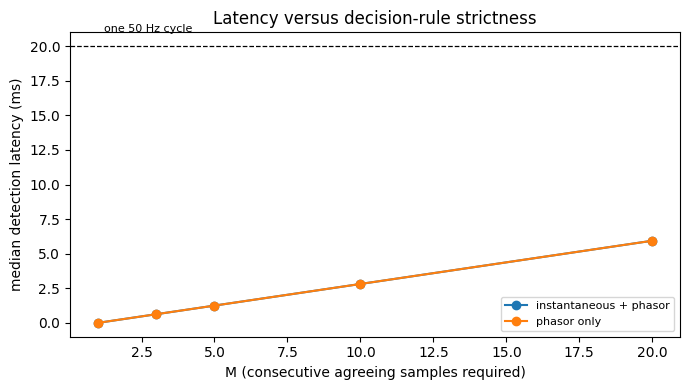


Reading: both feature sets declare the fault type within a few sample intervals, well inside a
single cycle. The phasor path does not wait for a fully post-fault estimation window, because a
window straddling the inception instant is already informative, so the median is the same for
the two feature sets at every M.

The tail is a different matter. p90 and max differ between the two sets, but the SIGN of that
difference is not stable across regenerations of the dataset - with a few hundred fault runs the
maximum is effectively a single sample. Report the tail, but do not draw a conclusion from it.

The wider point is that latency is a curve in M rather than a single number - a system reporting
'detection in X ms' without stating its decision rule has reported nothing - and that this curve
cannot be measured at all on a dataset with no pre-fault period.


In [20]:
PHASOR    = ['Im','Vm','Pai','Pav','Fi','Fv']
SAMPLE_MS = 1000/FS
CYCLE_MS  = 1000/F0

gen['run_id'] = (gen.time_stamp.diff().fillna(0) < 0).cumsum()
print(f'runs found: {gen.run_id.nunique()}   sample interval {SAMPLE_MS:.2f} ms   '
      f'one cycle {CYCLE_MS:.0f} ms')

def fit_latency_model(feat_set):
    nf = gen[gen.fault_types == 'NF']
    mu, sd = nf[feat_set].mean(), nf[feat_set].std().replace(0, 1)
    tr = gen_post.sample(frac=.8, random_state=RS)
    m = RandomForestClassifier(random_state=RS, n_jobs=-1).fit((tr[feat_set]-mu)/sd, tr['y'])
    return m, mu, sd

def latency_runs(feat_set, M):
    mdl, mu, sd = LAT_CACHE[tuple(feat_set)]
    rows = []
    for _, g in gen.groupby('run_id'):
        if g.fault_types.iloc[0] == 'NF':
            continue
        pred  = mdl.predict((g[feat_set]-mu)/sd)
        truth = g['y'].iloc[0]
        t, t0 = g.time_stamp.values, g.t_fault.iloc[0]
        ok, lat = 0, np.nan
        for i in np.where(t >= t0)[0]:
            ok = ok + 1 if pred[i] == truth else 0
            if ok >= M:
                lat = (t[i]-t0)*1000
                break
        rows.append((g.fault_types.iloc[0], lat))
    return pd.DataFrame(rows, columns=['fault_types','latency_ms'])

LAT_CACHE = {tuple(f): fit_latency_model(f) for f in (FEATS, PHASOR)}

print(f"\n{'M':>3}{'set':>26}{'declared':>10}{'median':>9}{'p90':>8}{'max':>8}")
store = {}
for M in [1, 3, 5, 10, 20]:
    for f, name in [(FEATS,'instantaneous + phasor'), (PHASOR,'phasor only')]:
        L = latency_runs(f, M)
        ok = L.dropna()
        store[(M, name)] = ok
        print(f'{M:>3}{name:>26}{len(ok):>6}/{len(L):<4}'
              f'{ok.latency_ms.median():9.2f}{ok.latency_ms.quantile(.9):8.2f}{ok.latency_ms.max():8.2f}')

print('\nper fault type at M = 5, instantaneous + phasor (ms after inception)')
print(store[(5,'instantaneous + phasor')].groupby('fault_types')['latency_ms']
      .agg(['count','median','mean','max']).round(2).to_string())

plt.figure(figsize=(7,4))
for name in ['instantaneous + phasor', 'phasor only']:
    xs = [1,3,5,10,20]
    ys = [store[(M,name)].latency_ms.median() for M in xs]
    plt.plot(xs, ys, 'o-', label=name)
plt.axhline(CYCLE_MS, ls='--', c='k', lw=.9)
plt.text(1.2, CYCLE_MS*1.05, 'one 50 Hz cycle', fontsize=8)
plt.xlabel('M (consecutive agreeing samples required)')
plt.ylabel('median detection latency (ms)')
plt.title('Latency versus decision-rule strictness')
plt.legend(fontsize=8)
plt.tight_layout()
plt.show()

print('''
Reading: both feature sets declare the fault type within a few sample intervals, well inside a
single cycle. The phasor path does not wait for a fully post-fault estimation window, because a
window straddling the inception instant is already informative, so the median is the same for
the two feature sets at every M.

The tail is a different matter. p90 and max differ between the two sets, but the SIGN of that
difference is not stable across regenerations of the dataset - with a few hundred fault runs the
maximum is effectively a single sample. Report the tail, but do not draw a conclusion from it.

The wider point is that latency is a curve in M rather than a single number - a system reporting
'detection in X ms' without stating its decision rule has reported nothing - and that this curve
cannot be measured at all on a dataset with no pre-fault period.''')

### Cell 21 — Summary of findings

In [21]:
print('''
1. Reproduction    the headline ensemble result reproduces within 0.1 points.
2. Data defect     370 rows carry placeholder phasors (Vm = Im = 1.0); the base paper
                   leaves this PMU warm-up window in the training data.
3. Audit I/II      the reported model ranking is largely a preprocessing artefact:
                   SVC-OvO drops sharply once scaling is removed and lands near the paper's
                   figure, while SVC-OvR is weak in both columns because of its linear kernel.
4. Audit III       the benchmark is saturated - a single feature with a depth-4 tree is
                   competitive with the full ensemble, and accuracy degrades sharply once
                   train and test are separated along the timeline.
5. Robustness      accuracy under AWGN, packet loss and false data injection quantifies how
                   much of the headline number survives a realistic PMU stream.
6. Replacement     a parametric generator sweeping fault location, resistance, inception
                   angle, source strength and loading produces a benchmark that is NOT
                   saturated, and that supports a detection-latency metric the original
                   dataset cannot support.
''')


1. Reproduction    the headline ensemble result reproduces within 0.1 points.
2. Data defect     370 rows carry placeholder phasors (Vm = Im = 1.0); the base paper
                   leaves this PMU warm-up window in the training data.
3. Audit I/II      the reported model ranking is largely a preprocessing artefact:
                   SVC-OvO drops sharply once scaling is removed and lands near the paper's
                   figure, while SVC-OvR is weak in both columns because of its linear kernel.
4. Audit III       the benchmark is saturated - a single feature with a depth-4 tree is
                   competitive with the full ensemble, and accuracy degrades sharply once
                   train and test are separated along the timeline.
5. Robustness      accuracy under AWGN, packet loss and false data injection quantifies how
                   much of the headline number survives a realistic PMU stream.
6. Replacement     a parametric generator sweeping fault location, resistan

## Part E — Paper artefacts

Cells 22--25 are only needed when preparing the manuscript. They produce
the publication figures and, if a Simulink model is available, the
electromagnetic-transient cross-validation.

### Cell 22 — publication figures (vector PDF)

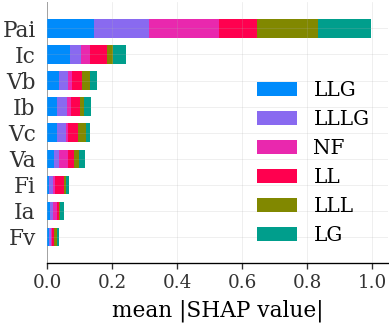

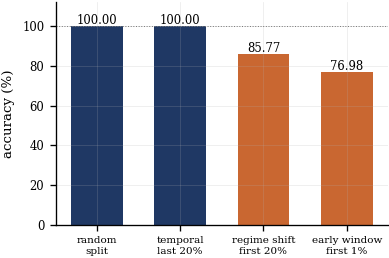

Fig 3 : {'random split': 100.0, 'temporal last 20%': 100.0, 'regime shift first 20%': 85.77, 'early window first 1%': 76.98}


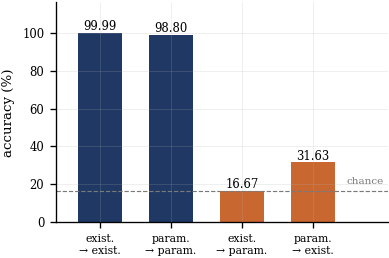

Fig 5 : [99.99, 98.8, 16.67, 31.63]


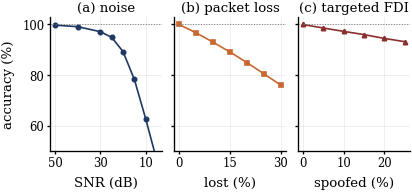

Fig 6 noise : [99.74, 99.12, 97.15, 94.9, 89.28, 78.3, 62.77, 46.01]
Fig 6 loss  : [100.0, 96.74, 93.04, 89.15, 84.95, 80.54, 76.03]
Fig 6 fdi   : [100.0, 98.61, 97.28, 96.0, 94.49, 93.22]


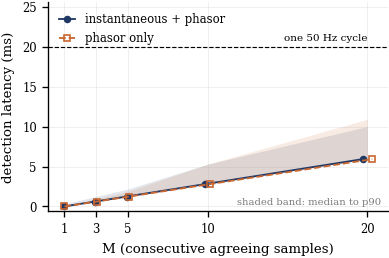

fig2_shap.pdf               11.6 kB
fig3_protocol.pdf           12.2 kB
fig4b_waveform.pdf MISSING
fig5_transfer.pdf           11.1 kB
fig6_perturbation.pdf       14.3 kB
fig7_latency.pdf            12.4 kB


In [22]:
import matplotlib as mpl
import matplotlib.pyplot as plt

mpl.rcParams.update({
    'font.family': 'serif', 'font.serif': ['Times New Roman', 'DejaVu Serif'],
    'font.size': 8, 'axes.labelsize': 8, 'axes.titlesize': 8,
    'xtick.labelsize': 7, 'ytick.labelsize': 7, 'legend.fontsize': 7,
    'axes.grid': True, 'grid.alpha': 0.3, 'grid.linewidth': 0.4,
    'axes.spines.top': False, 'axes.spines.right': False,
    'lines.linewidth': 1.1, 'lines.markersize': 3.5,
    'figure.dpi': 120, 'savefig.bbox': 'tight', 'savefig.pad_inches': 0.02,
    'pdf.fonttype': 42,
})
COL, DCOL, H = 3.45, 7.10, 2.35
NAVY, ORANGE, GREY = '#1F3864', '#C96731', '#7A7A7A'


try:
    import shap
    _ = sv, sample
    plt.figure(figsize=(COL, 2.9))
    shap.summary_plot(sv, sample, plot_type='bar', class_names=CLASSES,
                      show=False, plot_size=None)
    plt.xlabel('mean |SHAP value|')
    plt.tight_layout()
    plt.savefig('fig2_shap.pdf')
    plt.show()
except (NameError, ImportError):
    print('fig2 skipped - run Cell 11 first (needs shap, sv, sample)')


from sklearn.model_selection import train_test_split

_tr_i, _te_i = train_test_split(d.index, test_size=.2, random_state=RS, stratify=d['y'])
prot = [
    ('random\nsplit',       rf_acc(d.loc[_tr_i], d.loc[_te_i])[0]),
    ('temporal\nlast 20%',  rf_acc(*split_by_time(d, .8, False))[0]),
    ('regime shift\nfirst 20%', rf_acc(*split_by_time(d, .2, True))[0]),
    ('early window\nfirst 1%',  rf_acc(*split_by_time(d, .01, True))[0]),
]
labels, vals = zip(*prot)

fig, ax = plt.subplots(figsize=(COL, H))
bars = ax.bar(range(4), vals, color=[NAVY, NAVY, ORANGE, ORANGE], width=.62)
for b, v in zip(bars, vals):
    ax.text(b.get_x()+b.get_width()/2, v+1, f'{v:.2f}', ha='center', fontsize=7)
ax.set_xticks(range(4))
ax.set_xticklabels(labels, fontsize=6.2)
ax.set_ylabel('accuracy (%)')
ax.set_ylim(0, 112)
ax.axhline(100, ls=':', c=GREY, lw=.6)
fig.tight_layout()
fig.savefig('fig3_protocol.pdf')
plt.show()
print('Fig 3 :', dict(zip([l.replace(chr(10),' ') for l in labels], vals)))


from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

def _acc(Atr, ytr_, Ate, yte_):
    m = RandomForestClassifier(random_state=RS, n_jobs=-1).fit(Atr, ytr_)
    return accuracy_score(yte_, m.predict(Ate))*100

A1, A2, y1, y2 = train_test_split(Ab, yb, test_size=.2, random_state=RS, stratify=yb)
B1, B2, z1, z2 = train_test_split(Ag, yg, test_size=.2, random_state=RS, stratify=yg)
T = [_acc(A1, y1, A2, y2), _acc(B1, z1, B2, z2),
     _acc(Ab, yb, Ag, yg), _acc(Ag, yg, Ab, yb)]
names = ['exist.\n\u2192 exist.', 'param.\n\u2192 param.',
         'exist.\n\u2192 param.', 'param.\n\u2192 exist.']

fig, ax = plt.subplots(figsize=(COL, H))
bars = ax.bar(range(4), T, color=[NAVY, NAVY, ORANGE, ORANGE], width=.62)
for b, v in zip(bars, T):
    ax.text(b.get_x()+b.get_width()/2, v+1.5, f'{v:.2f}', ha='center', fontsize=7)
ax.axhline(100/len(CLASSES), ls='--', c=GREY, lw=.7)
ax.set_xlim(-.62, 4.05)
ax.text(4.0, 100/len(CLASSES)+2.5, 'chance', fontsize=6.2, ha='right',
        va='bottom', color=GREY)
ax.set_xticks(range(4))
ax.set_xticklabels(names, fontsize=6.5)
ax.set_ylabel('accuracy (%)')
ax.set_ylim(0, 116)
fig.tight_layout()
fig.savefig('fig5_transfer.pdf')
plt.show()
print('Fig 5 :', [round(v, 2) for v in T])


import numpy as np
_rng = np.random.default_rng(0)
clean = accuracy_score(yte, base.predict(Xr_te))*100
dom = int(np.argmax(base.feature_importances_))

snrs = [50, 40, 30, 25, 20, 15, 10, 5]
a_noise = [accuracy_score(yte, base.predict(awgn(Xr_te, s, _rng)))*100 for s in snrs]
losses = [0, .05, .10, .15, .20, .25, .30]
a_loss = [clean if f == 0 else
          accuracy_score(yte, base.predict(packet_loss(Xr_te, f, _rng)))*100 for f in losses]
fracs = [0, .05, .10, .15, .20, .25]
a_fdi = [clean if f == 0 else
         accuracy_score(yte, base.predict(fdi(Xr_te, f, 2.0, _rng, col=dom)))*100 for f in fracs]

import matplotlib as mpl
with mpl.rc_context({'font.size': 8, 'axes.labelsize': 8, 'axes.titlesize': 8,
                     'xtick.labelsize': 7, 'ytick.labelsize': 7}):
    fig, axes = plt.subplots(1, 3, figsize=(COL, 1.62), sharey=True)
    axes[0].plot(snrs, a_noise, 'o-', c=NAVY, ms=2.6, lw=1.0)
    axes[0].invert_xaxis()
    axes[0].set_xlabel('SNR (dB)')
    axes[0].set_title('(a) noise', pad=3)
    axes[0].set_xticks([50, 30, 10])
    axes[1].plot([f*100 for f in losses], a_loss, 's-', c=ORANGE, ms=2.6, lw=1.0)
    axes[1].set_xlabel('lost (%)')
    axes[1].set_title('(b) packet loss', pad=3)
    axes[1].set_xticks([0, 15, 30])
    axes[2].plot([f*100 for f in fracs], a_fdi, '^-', c='#8B2E2E', ms=2.6, lw=1.0)
    axes[2].set_xlabel('spoofed (%)')
    axes[2].set_title('(c) targeted FDI', pad=3)
    axes[2].set_xticks([0, 10, 20])
    for a in axes:
        a.set_ylim(50, 103)
        a.axhline(clean, ls=':', c=GREY, lw=.6)
        a.tick_params(length=2, pad=1.5)
    axes[0].set_ylabel('accuracy (%)')
    fig.tight_layout(pad=.25, w_pad=.4)
    fig.savefig('fig6_perturbation.pdf')
    plt.show()
print('Fig 6 noise :', [round(v, 2) for v in a_noise])
print('Fig 6 loss  :', [round(v, 2) for v in a_loss])
print('Fig 6 fdi   :', [round(v, 2) for v in a_fdi])


Ms = [1, 3, 5, 10, 20]
fig, ax = plt.subplots(figsize=(COL, H))
for i, (name, c, mk, ls) in enumerate(
        [('instantaneous + phasor', NAVY, 'o', '-'),
         ('phasor only', ORANGE, 's', '--')]):
    med = [store[(M, name)].latency_ms.median() for M in Ms]
    p90 = [store[(M, name)].latency_ms.quantile(.9) for M in Ms]
    off = [M*(1 + (i-0.5)*0.03) for M in Ms]
    ax.plot(off, med, mk, ls=ls, c=c, label=name, mfc='none' if i else c)
    ax.fill_between(Ms, med, p90, color=c, alpha=.13, lw=0)
ax.axhline(CYCLE_MS, ls='--', c='k', lw=.7)
ax.text(20, CYCLE_MS*1.04, 'one 50 Hz cycle', fontsize=6.2, ha='right')
ax.set_ylim(-.6, CYCLE_MS*1.28)
ax.set_xlabel('M (consecutive agreeing samples)')
ax.set_ylabel('detection latency (ms)')
ax.set_xticks(Ms)
ax.legend(frameon=False, loc='upper left', handlelength=1.4)
ax.text(.98, .02, 'shaded band: median to p90', transform=ax.transAxes,
        ha='right', va='bottom', fontsize=6, color=GREY)
fig.tight_layout()
fig.savefig('fig7_latency.pdf')
plt.show()

import os
figs = ['fig2_shap.pdf', 'fig3_protocol.pdf', 'fig4b_waveform.pdf',
        'fig5_transfer.pdf', 'fig6_perturbation.pdf', 'fig7_latency.pdf']
for f in figs:
    print(f'{f:24} {os.path.getsize(f)/1024:7.1f} kB' if os.path.exists(f) else f'{f} MISSING')
try:
    from google.colab import files
    for f in figs:
        if os.path.exists(f):
            files.download(f)
except ImportError:
    pass

### Cell 23 — Figure 4: single-line diagram and generated waveform

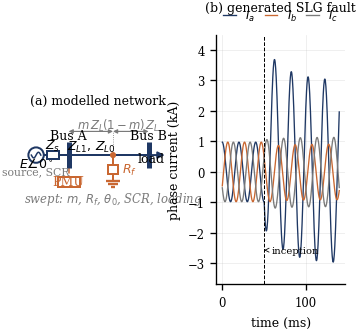

fig4_network_waveform.pdf  35.6 kB


In [23]:
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, Circle, FancyArrowPatch

NAVY, ORANGE, GREY = '#1F3864', '#C96731', '#7A7A7A'
LW = 1.2

fig = plt.figure(figsize=(3.45, 2.7))
gs = fig.add_gridspec(1, 2, width_ratios=[1.15, 1.0], wspace=0.32)

ax = fig.add_subplot(gs[0])
ax.set_axis_off()
ax.set_xlim(0, 100)
ax.set_ylim(0, 62)
ax.set_aspect('equal')
Y = 34
XS, XA, XF, XB, XL = 8, 30, 60, 84, 95

def wire(x0, x1, y0=Y, y1=None, c=NAVY, lw=LW, **kw):
    ax.plot([x0, x1], [y0, y1 if y1 is not None else y0], c=c, lw=lw,
            solid_capstyle='round', zorder=2, **kw)

ax.add_patch(Circle((XS, Y), 5.2, fc='none', ec=NAVY, lw=LW, zorder=3))
_t = np.linspace(-1, 1, 60)
ax.plot(XS + _t*3.2, Y + 1.9*np.sin(np.pi*_t), c=NAVY, lw=0.9, zorder=4)
ax.text(XS, Y-8.4, r'$E\angle 0^\circ$', ha='center', fontsize=7.5)
ax.text(XS, Y-13.0, 'source, SCR', ha='center', fontsize=6.5, color=GREY)

wire(XS+5.2, 15.5)
ax.add_patch(Rectangle((15.5, Y-2.6), 8, 5.2, fc='white', ec=NAVY, lw=LW, zorder=3))
ax.text(19.5, Y+4.4, r'$Z_s$', ha='center', fontsize=7.5)
wire(23.5, XA)

for x, name in [(XA, 'Bus A'), (XB, 'Bus B')]:
    ax.plot([x, x], [Y-9, Y+9], c=NAVY, lw=3.0, solid_capstyle='butt', zorder=3)
    ax.text(x, Y+11, name, ha='center', fontsize=7.5)

wire(XA, XB)
ax.text((XA+XF)/2, Y+3.2, r'$Z_{L1},\,Z_{L0}$', ha='center', fontsize=7.5)

ax.plot([XA, XA], [Y-9, Y-15], c=ORANGE, lw=0.9, ls='--', zorder=2)
ax.add_patch(Rectangle((XA-7.5, Y-21.5), 15, 6.5, fc='white', ec=ORANGE, lw=LW, zorder=3))
ax.text(XA, Y-18.2, 'PMU', ha='center', va='center', fontsize=7.5, color=ORANGE)

ax.add_patch(Circle((XF, Y), 1.5, fc=ORANGE, ec=ORANGE, zorder=5))
wire(XF, XF, Y, Y-7, c=ORANGE)
ax.add_patch(Rectangle((XF-3.4, Y-13), 6.8, 6, fc='white', ec=ORANGE, lw=LW, zorder=3))
ax.text(XF+6.2, Y-10, r'$R_f$', ha='left', va='center', fontsize=7.5, color=ORANGE)
wire(XF, XF, Y-13, Y-17.5, c=ORANGE)
for w, dy in [(5.0, 0), (3.2, 1.9), (1.6, 3.8)]:
    ax.plot([XF-w, XF+w], [Y-17.5-dy]*2, c=ORANGE, lw=1.4, solid_capstyle='butt')

def dim(x0, x1, y, label):
    ax.add_patch(FancyArrowPatch((x0, y), (x1, y), arrowstyle='<|-|>',
                 mutation_scale=5, lw=0.7, color=GREY, shrinkA=0, shrinkB=0))
    ax.text((x0+x1)/2, y+1.6, label, ha='center', fontsize=7.0, color=GREY)
ax.plot([XF, XF], [Y+1.5, Y+16], c=GREY, lw=0.5, ls=':', zorder=1)
dim(XA, XF, Y+16, r'$m\,Z_L$')
dim(XF, XB, Y+16, r'$(1-m)\,Z_L$')

ax.add_patch(FancyArrowPatch((XB, Y), (XL, Y), arrowstyle='-|>',
                           mutation_scale=8, lw=LW, color=NAVY, shrinkA=0, shrinkB=0))
ax.text(XL, Y-5.0, 'load', ha='right', fontsize=7.5)

ax.text(0, 2, r'swept: $m$, $R_f$, $\theta_0$, SCR, loading',
        fontsize=7.0, style='italic', color=GREY)
ax.set_title('(a) modelled network', fontsize=7.5)

ax2 = fig.add_subplot(gs[1])
r = run_case('LG', m=.4, Rf=1., theta0=0.6, scr=8., load=1., dur=.14, t_fault=.05)
for k, (p, c) in enumerate(zip('abc', [NAVY, ORANGE, GREY])):
    ax2.plot(r['t']*1000, r['I'][:, k]/1e3, c=c, lw=0.8, label=f'$I_{p}$')
ax2.axvline(r['t_fault']*1000, ls='--', c='k', lw=0.6)
lo, hi = ax2.get_ylim()
ax2.set_ylim(lo*1.12, hi*1.12)
ax2.annotate('inception', xy=(r['t_fault']*1000, lo*.78),
             xytext=(r['t_fault']*1000+9, lo*.78), fontsize=6.0, va='center',
             arrowprops=dict(arrowstyle='->', lw=0.5))
ax2.set_xlabel('time (ms)', fontsize=7.5)
ax2.set_ylabel('phase current (kA)', fontsize=7.5)
ax2.tick_params(axis='both', labelsize=7.0)
ax2.legend(ncol=3, frameon=False, loc='lower center', bbox_to_anchor=(.5, 1.02),
            handlelength=1.1, columnspacing=0.8, borderpad=0.1, fontsize=7.0)
ax2.set_title('(b) generated SLG fault', fontsize=7.5, pad=14)
ax2.grid(alpha=.3, lw=0.4)
for s in ('top', 'right'):
    ax2.spines[s].set_visible(False)

fig.savefig('fig4_network_waveform.pdf', bbox_inches='tight', pad_inches=0.02)
plt.show()

import os
print('fig4_network_waveform.pdf  %.1f kB' % (os.path.getsize('fig4_network_waveform.pdf')/1024))
try:
    from google.colab import files
    files.download('fig4_network_waveform.pdf')
except ImportError:
    pass

### Cell 24 — corrected SHAP and perturbation figures

`shap.summary_plot` hard-codes a font size roughly twice that of the rest
of the paper, and the noise sweep runs below the default axis floor.

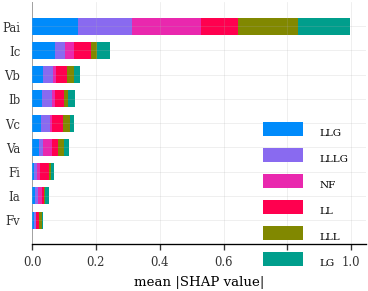

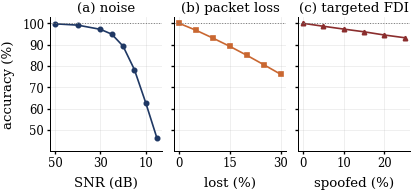

Fig. 6 drawn at 3.45 in wide; dominant input spoofed = Pai
y-axis floor set to 40.0  (lowest measured point 46.01)
fig2_shap.pdf              11.6 kB
fig6_perturbation.pdf      14.8 kB


In [24]:
import numpy as np
import matplotlib.pyplot as plt

NAVY, ORANGE, GREY = '#1F3864', '#C96731', '#7A7A7A'
COL, DCOL = 3.45, 7.10


import shap

shap.summary_plot(sv, sample, plot_type='bar', class_names=CLASSES,
                  show=False, plot_size=(COL, 2.75))
fig, ax = plt.gcf(), plt.gca()

ax.tick_params(axis='y', labelsize=7)
ax.tick_params(axis='x', labelsize=7)
ax.set_xlabel('mean |SHAP value|', fontsize=8)
ax.set_ylabel('')
for lbl in ax.get_yticklabels():
    lbl.set_fontsize(7)

leg = ax.get_legend()
if leg is not None:
    leg.set_frame_on(False)
    leg.set_title(None)
    for t in leg.get_texts():
        t.set_fontsize(6.2)
    leg.set_bbox_to_anchor((1.0, .58))

for s in ('top', 'right'):
    ax.spines[s].set_visible(False)
fig.set_size_inches(COL, 2.75)
fig.savefig('fig2_shap.pdf', bbox_inches='tight', pad_inches=0.02)
plt.show()


_rng = np.random.default_rng(0)
from sklearn.metrics import accuracy_score
clean = accuracy_score(yte, base.predict(Xr_te)) * 100
dom = int(np.argmax(base.feature_importances_))

snrs = [50, 40, 30, 25, 20, 15, 10, 5]
a_noise = [accuracy_score(yte, base.predict(awgn(Xr_te, s, _rng))) * 100 for s in snrs]
losses = [0, .05, .10, .15, .20, .25, .30]
a_loss = [clean if f == 0 else
          accuracy_score(yte, base.predict(packet_loss(Xr_te, f, _rng))) * 100 for f in losses]
fracs = [0, .05, .10, .15, .20, .25]
a_fdi = [clean if f == 0 else
         accuracy_score(yte, base.predict(fdi(Xr_te, f, 2.0, _rng, col=dom))) * 100 for f in fracs]

ymin = min(a_noise + a_loss + a_fdi) - 6

import matplotlib as mpl
with mpl.rc_context({'font.size': 8, 'axes.labelsize': 8, 'axes.titlesize': 8,
                     'xtick.labelsize': 7, 'ytick.labelsize': 7,
                     'axes.linewidth': .6}):
    fig, axes = plt.subplots(1, 3, figsize=(COL, 1.62), sharey=True)
    axes[0].plot(snrs, a_noise, 'o-', c=NAVY, ms=2.6, lw=1.0)
    axes[0].invert_xaxis()
    axes[0].set_xlabel('SNR (dB)')
    axes[0].set_title('(a) noise', pad=3)
    axes[0].set_xticks([50, 30, 10])
    axes[1].plot([f*100 for f in losses], a_loss, 's-', c=ORANGE, ms=2.6, lw=1.0)
    axes[1].set_xlabel('lost (%)')
    axes[1].set_title('(b) packet loss', pad=3)
    axes[1].set_xticks([0, 15, 30])
    axes[2].plot([f*100 for f in fracs], a_fdi, '^-', c='#8B2E2E', ms=2.6, lw=1.0)
    axes[2].set_xlabel('spoofed (%)')
    axes[2].set_title('(c) targeted FDI', pad=3)
    axes[2].set_xticks([0, 10, 20])
    for a in axes:
        a.set_ylim(ymin, 103)
        a.axhline(clean, ls=':', c=GREY, lw=.6)
        a.grid(alpha=.3, lw=.4)
        a.tick_params(length=2, pad=1.5)
        for s in ('top', 'right'):
            a.spines[s].set_visible(False)
    axes[0].set_ylabel('accuracy (%)')
    axes[0].set_yticks([50, 60, 70, 80, 90, 100])
    fig.tight_layout(pad=.25, w_pad=.4)
    fig.savefig('fig6_perturbation.pdf', bbox_inches='tight', pad_inches=0.02)
    plt.show()

print(f'Fig. 6 drawn at {COL} in wide; dominant input spoofed = {FEATS[dom]}')

print(f'y-axis floor set to {ymin:.1f}  (lowest measured point {min(a_noise+a_loss+a_fdi):.2f})')

import os
for f in ['fig2_shap.pdf', 'fig6_perturbation.pdf']:
    print(f'{f:24} {os.path.getsize(f)/1024:6.1f} kB')
try:
    from google.colab import files
    files.download('fig2_shap.pdf')
    files.download('fig6_perturbation.pdf')
except ImportError:
    pass

### Cell 25 — EMT cross-validation (optional)

Requires `emt_<CLASS>.mat` files exported from the Simulink model. Skip
this cell if you have not built the model.

post-fault RMS current, analytic vs EMT

 cls phase  analytic       emt  diff_pct
  LG     a    1854.0    1865.3      -0.6
  LG     b     652.3     648.0       0.7
  LG     c     817.8     818.6      -0.1
  LL     a     696.0     694.5       0.2
  LL     b    2370.2    2370.2       0.0
  LL     c    1833.5    1824.2       0.5
 LLG     a     760.5     755.4       0.7
 LLG     b    2371.2    2352.0       0.8
 LLG     c    2069.2    2091.6      -1.1
 LLL     a    2405.2    2417.9      -0.5
 LLL     b    2410.0    2421.3      -0.5
 LLL     c    2412.9    2416.3      -0.1
LLLG     a    2405.2    2417.9      -0.5
LLLG     b    2410.0    2421.3      -0.5
LLLG     c    2412.9    2416.3      -0.1
  NF     a     696.0     695.5       0.1
  NF     b     696.1     695.3       0.1
  NF     c     694.0     695.4      -0.2

mean |difference| = 0.41%   max = 1.07%

dc time constant (ms), worst-affected phase
 cls phase  tau_analytic_ms  tau_emt_ms
  LG     a            21.19       26.45
  LL     b    


LLL vs LLLG in EMT: max difference 0.000%  (indistinguishable)
phase offset applied: -90.7 deg
post-fault waveform residual: 1.49%


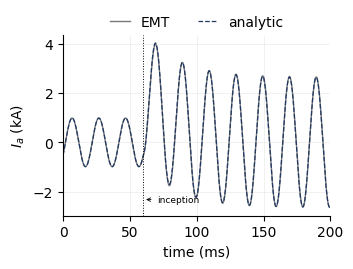


saved -> emt_validation.csv
validation 2  SLG 1868 A < 3-phase 2418 A            OK
validation 3  Rf sweep (LG, fault component): ['1868', '1847', '1756', '1636', '1403', '916'] A    monotone decreasing
validation 4  m  sweep (LG, fault component): ['7849', '3079', '1858', '1391', '1173'] A    monotone decreasing
validation 5  LLL == LLLG                          OK

terminal current (load superposed), Rf sweep, for contrast:
    ['1859', '1857', '1836', '1793', '1681', '1380'] A  <- not monotone, which is why the checks use the fault component

numbers for Section IV-D:
  SLG 1868 A vs three-phase 2418 A
  Rf: 1868 A at 0 ohm -> 916 A at 50 ohm
  m : 7849 A at m=0.05 -> 1173 A at m=0.95


In [25]:
import numpy as np, pandas as pd
from scipy.io import loadmat
import matplotlib.pyplot as plt

CASE = dict(m=.5, Rf=1., theta0=0., scr=10., load=1., dur=.25, t_fault=.06)
F0 = 50.0


def rms_after(t, x, t0, skip_cycles=4):
    lo = t0 + skip_cycles/F0
    win = (t >= lo) & (t <= lo + 4/F0)
    return float(np.sqrt(np.mean(x[win]**2)))


def dc_tau(t, x, t0, fs_hint=None):
    N = max(8, int(round((1/F0) / np.median(np.diff(t)))))
    off = pd.Series(x).rolling(N, center=True).mean().values
    win = (t > t0 + .002) & (t < t0 + .12) & np.isfinite(off)
    tt, oo = t[win] - t0, np.abs(off[win])
    keep = oo > .02*np.nanmax(oo)
    if keep.sum() < 10:
        return np.nan
    slope = np.polyfit(tt[keep], np.log(oo[keep]), 1)[0]
    return float(-1/slope) if slope < 0 else np.nan


rows = []
for cls in CLASSES:
    try:
        M = loadmat(f'emt_{cls}.mat')
    except FileNotFoundError:
        print(f'{cls:6} emt_{cls}.mat not found - skipped')
        continue
    te = np.asarray(M['tout']).ravel()
    Ie = np.asarray(M['Idata'])
    if Ie.shape[0] != te.size:
        Ie = Ie.T

    r = run_case(cls, **CASE)
    ta, Ia_ = r['t'], r['I']
    t0 = CASE['t_fault']

    for k, ph in enumerate('abc'):
        a = rms_after(ta, Ia_[:, k], t0)
        e = rms_after(te, Ie[:, k], t0)
        rows.append(dict(cls=cls, phase=ph, analytic=a, emt=e,
                         diff_pct=100*(a-e)/e if e else np.nan))

    if cls != 'NF':
        j = int(np.argmax([np.ptp(Ie[te > t0, k]) for k in range(3)]))
        rows[-3+j]['tau_analytic_ms'] = 1e3*dc_tau(ta, Ia_[:, j], t0)
        rows[-3+j]['tau_emt_ms'] = 1e3*dc_tau(te, Ie[:, j], t0)

R = pd.DataFrame(rows)
if len(R):
    print('post-fault RMS current, analytic vs EMT\n')
    print(R[['cls', 'phase', 'analytic', 'emt', 'diff_pct']]
          .to_string(index=False, float_format=lambda v: f'{v:9.1f}'))
    print(f'\nmean |difference| = {R.diff_pct.abs().mean():.2f}%   '
          f'max = {R.diff_pct.abs().max():.2f}%')
    if 'tau_emt_ms' in R:
        T = R.dropna(subset=['tau_emt_ms'])
        print('\ndc time constant (ms), worst-affected phase')
        print(T[['cls', 'phase', 'tau_analytic_ms', 'tau_emt_ms']]
              .to_string(index=False, float_format=lambda v: f'{v:8.2f}'))

    p = R[R.cls.isin(['LLL', 'LLLG'])].pivot_table(index='phase', columns='cls',
                                                    values='emt')
    if {'LLL', 'LLLG'} <= set(p.columns):
        d = 100*(p['LLL'] - p['LLLG']).abs()/p['LLLG']
        print(f'\nLLL vs LLLG in EMT: max difference {d.max():.3f}%  '
              f'({"indistinguishable" if d.max() < 1 else "CHECK R0/L0"})')

    if 'LG' in set(R.cls):
        M = loadmat('emt_LG.mat')
        te = np.asarray(M['tout']).ravel()
        Ie = np.asarray(M['Idata'])
        if Ie.shape[0] != te.size:
            Ie = Ie.T
        t0 = CASE['t_fault']
        W0 = 2*np.pi*F0

        def _phase(t, x, lo, hi):
            w = (t > lo) & (t < hi)
            c = np.trapz(x[w]*np.cos(W0*t[w]), t[w])
            s = np.trapz(x[w]*np.sin(W0*t[w]), t[w])
            return np.arctan2(-s, c)

        ra  = run_case('LG', **CASE)
        d   = _phase(te, Ie[:, 0], .005, t0-.005) \
            - _phase(ra['t'], ra['I'][:, 0], .005, t0-.005)
        r   = run_case('LG', **dict(CASE, theta0=CASE['theta0']+d))
        print(f'phase offset applied: {np.degrees(d):+.1f} deg')

        ia = np.interp(te, r['t'], r['I'][:, 0])
        w  = te > t0 + 4/F0
        print('post-fault waveform residual: %.2f%%'
              % (100*np.sqrt(np.mean((ia[w]-Ie[w, 0])**2))
                     / np.sqrt(np.mean(Ie[w, 0]**2))))

        fig, ax = plt.subplots(figsize=(3.45, 2.35))
        ax.plot(te*1e3, Ie[:, 0]/1e3, lw=1.0, c='#7A7A7A', label='EMT')
        ax.plot(r['t']*1e3, r['I'][:, 0]/1e3, lw=.9, c='#1F3864', ls='--',
                label='analytic')
        ax.axvline(t0*1e3, ls=':', c='k', lw=.7)
        lo, hi = ax.get_ylim()
        ax.annotate('inception', xy=(t0*1e3, lo*.78),
                    xytext=(t0*1e3+10, lo*.78), fontsize=6.5, va='center',
                    arrowprops=dict(arrowstyle='->', lw=.6))
        ax.set_xlabel('time (ms)')
        ax.set_ylabel('$I_a$ (kA)')
        ax.legend(frameon=False, ncol=2, loc='upper center',
                  bbox_to_anchor=(.5, 1.18), handlelength=1.4)
        ax.set_xlim(0, 200)
        ax.grid(alpha=.3, lw=.4)
        for sp in ('top', 'right'):
            ax.spines[sp].set_visible(False)
        fig.savefig('fig8_emt_overlay.pdf', bbox_inches='tight', pad_inches=.02)
        plt.show()

    R.to_csv('emt_validation.csv', index=False)
    print('\nsaved -> emt_validation.csv')


def fault_component(kind, m=.5, Rf=.5, scr=10., load=1., Vll=132.):
    Vph = Vll*1e3/np.sqrt(3)
    Zbase = (Vll*1e3)**2/100e6
    ZL1 = (0.03+0.30j)*Zbase
    ZL0 = 3.0*ZL1.real + 2.7j*ZL1.imag

    Zs1, Zs0 = ZL1/scr, 1.2*ZL1/scr

    Zload = Vph/(load*Vph/abs(ZL1)*0.6 + 1e-9)

    Zsrc1, Zsrc0 = Zs1 + m*ZL1, Zs0 + m*ZL0
    Zrem1, Zrem0 = (1-m)*ZL1 + Zload, (1-m)*ZL0 + Zload

    par = lambda a, b: a*b/(a+b)
    Z1th = Z2th = par(Zsrc1, Zrem1)
    Z0th = par(Zsrc0, Zrem0)
    Vf0 = Vph*Zrem1/(Zsrc1+Zrem1)

    I0, I1, I2 = seq_currents(kind, Z1th, Z2th, Z0th, Vf0, Rf)
    return np.abs(A_MAT @ np.array([I0, I1, I2]))


def validate_fault_component(verbose=True):
    ok = True

    i3 = fault_component('LLL', m=.5, Rf=0.)[0]
    i1 = fault_component('LG',  m=.5, Rf=0.)[0]
    c2 = i1 < i3
    ok &= c2

    rf_sweep = [fault_component('LG', Rf=x)[0] for x in [0, 1, 5, 10, 20, 50]]
    c3 = all(np.diff(rf_sweep) < 0)
    ok &= c3

    m_sweep = [fault_component('LG', m=x)[0] for x in [.05, .25, .5, .75, .95]]
    c4 = all(np.diff(m_sweep) < 0)
    ok &= c4

    lll  = fault_component('LLL',  m=.5, Rf=1.)
    lllg = fault_component('LLLG', m=.5, Rf=1.)
    c5 = np.allclose(lll, lllg)
    ok &= c5

    if verbose:
        print('validation 2  SLG %.0f A < 3-phase %.0f A            %s'
              % (i1, i3, 'OK' if c2 else 'FAIL'))
        print('validation 3  Rf sweep (LG, fault component):',
              [f'{v:.0f}' for v in rf_sweep], 'A   ',
              'monotone decreasing' if c3 else 'NOT MONOTONE')
        print('validation 4  m  sweep (LG, fault component):',
              [f'{v:.0f}' for v in m_sweep], 'A   ',
              'monotone decreasing' if c4 else 'NOT MONOTONE')
        print('validation 5  LLL == LLLG                          %s'
              % ('OK' if c5 else 'FAIL'))
        print('\nterminal current (load superposed), Rf sweep, for contrast:')
        print('   ', [f'{abs(run_case("LG", m=.5, Rf=x)["Iph"][0]):.0f}'
                      for x in [0, 1, 5, 10, 20, 50]], 'A  <- not monotone,'
              ' which is why the checks use the fault component')
    assert ok, 'generator validation failed'
    return dict(slg=i1, three_ph=i3, rf_sweep=rf_sweep, m_sweep=m_sweep)


_v = validate_fault_component()
print('\nnumbers for Section IV-D:')
print(f"  SLG {_v['slg']:.0f} A vs three-phase {_v['three_ph']:.0f} A")
print(f"  Rf: {_v['rf_sweep'][0]:.0f} A at 0 ohm -> {_v['rf_sweep'][-1]:.0f} A at 50 ohm")
print(f"  m : {_v['m_sweep'][0]:.0f} A at m=0.05 -> {_v['m_sweep'][-1]:.0f} A at m=0.95")